In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
raw_data=pd.read_excel(r'C:\Users\Jose.Hurtado\Downloads\raw-data_TorchX110-1JOU_2026-11-01_2026-11-27.xlsx')
raw_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 8384 entries, 0 to 8383
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Created    8384 non-null   str    
 1   Message    8384 non-null   str    
 2   Status     8384 non-null   str    
 3   Type       8384 non-null   str    
 4   Alarm      0 non-null      float64
 5   Ignition   6344 non-null   str    
 6   Latitude   6344 non-null   float64
 7   Longitude  6344 non-null   float64
 8   Speed      6344 non-null   float64
dtypes: float64(4), str(5)
memory usage: 589.6 KB


In [3]:
print('IMEI',raw_data.iloc[0,2][17:32])

IMEI 867284063851903


In [4]:
print(raw_data.loc[0])

Created                                2026-11-27 18:20:04.644
Message      [{"Protocol":"0x2626","MessageType":"SignInMes...
Status       0x262601002300E9086728406385190301020000260525...
Type                                             SignInMessage
Alarm                                                      NaN
Ignition                                                   NaN
Latitude                                                   NaN
Longitude                                                  NaN
Speed                                                      NaN
Name: 0, dtype: object


In [5]:
raw_data_codes=[]

for i in range(0,raw_data.shape[0]):
    raw_data_codes.append(raw_data.iloc[i,2][6:8])

raw_data['Codes']=raw_data_codes
raw_data['Codes'].value_counts()

Codes
02    6184
01     903
03     699
11     425
04     160
09      13
Name: count, dtype: int64

In [6]:
torch_codes_02=raw_data[raw_data['Codes'].str.contains('02')]
torch_codes_04=raw_data[raw_data['Codes'].str.contains('04')]
torch_codes_0204=pd.concat([torch_codes_02,torch_codes_04])

torch_codes_0204.to_csv(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\data\zonar\torch_analysis.csv',sep=',')

ignition_on_interval=[]
ignition_off_interval=[]
io=[]
odometer=[]
date=[]
ext_ps=[]
speed=[]
#over_speed=[]
gnss=[]
#a_code=[]
#direction=[]
accum_fuel_consumption=[]
#instant_fuel_consumption=[]
rpm=[]
cool_temp=[]
#air_in_flow_temp=[]
engine_load=[]
remain_fuel_rate=[]

for i in range(0,torch_codes_0204.shape[0]):
    ignition_on_interval.append(int(torch_codes_0204.iloc[i,2][32:36],16))
    ignition_off_interval.append(int(torch_codes_0204.iloc[i,2][36:40],16))
    io.append(bin(int(torch_codes_0204.iloc[i,2][64:68],16)))
    odometer.append(int(torch_codes_0204.iloc[i,2][72:80],16))
    date.append(torch_codes_0204.iloc[i,2][82:94])
    ext_ps.append((float(int(torch_codes_0204.iloc[i,2][126:130])))/100)
    speed.append(int(torch_codes_0204.iloc[i,2][131:133]))    
    #over_speed.append(torch_codes_0204.iloc[i,2])
    gnss.append(int(torch_codes_0204.iloc[i,2][51:52],16))
    #a_code.append(torch_codes_0204.iloc[])
    #direction.append(torch_codes_0204.iloc[i,2])
    accum_fuel_consumption.append(float(int(torch_codes_0204.iloc[i,2][134:142],16))/1000)
    #instant_fuel_consumption.append(torch_codes_0204.iloc[i,2]) invalid!
    rpm.append(int(torch_codes_0204.iloc[i,2][150:154],16))
    cool_temp.append(int(torch_codes_0204.iloc[i,2][158:160],16))
    #air_in_flow_temp.append(torch_codes_0204.iloc[i,2])
    engine_load.append(int(torch_codes_0204.iloc[i,2][162:164],16))
    remain_fuel_rate.append(torch_codes_0204.iloc[i,2][166:168])

torch_codes_0204['i_on']=ignition_on_interval
torch_codes_0204['i_off']=ignition_off_interval
torch_codes_0204['io']=io
torch_codes_0204['odometer']=odometer
torch_codes_0204['date']=date
torch_codes_0204['ext_ps']=ext_ps
torch_codes_0204['speed']=speed
torch_codes_0204['gnss']=gnss
torch_codes_0204['acc_fuel_c']=accum_fuel_consumption
torch_codes_0204['rpm']=rpm
torch_codes_0204['cool_temp']=cool_temp
torch_codes_0204['remain_fuel']=remain_fuel_rate
torch_codes_0204['engine_load']=engine_load

torch_codes_0204_ordered=torch_codes_0204.sort_values('date',ascending=True)

print(torch_codes_0204_ordered[['i_on','i_off','io','odometer','date','ext_ps','speed','acc_fuel_c','rpm','remain_fuel','gnss','cool_temp','engine_load']])

      i_on  i_off                 io  odometer          date  ext_ps  speed  \
8382    25    600                0b0         0  261123173647   12.81      0   
8377    25    600                0b0         0  261123173856   12.64      0   
8371    25    600                0b0         0  261123174858   13.06      0   
8366    25    600                0b0         0  261123175858   13.08      0   
8361    25    600                0b0         0  261123180858   12.98      0   
...    ...    ...                ...       ...           ...     ...    ...   
16      25    600  0b100000000000000   1028989  261127175558   13.65      0   
14      25    600  0b100000000000000   1028989  261127175623   13.53      0   
12      25    600                0b0   1028989  261127175647   13.44      0   
6       25    600                0b0   1028989  261127180648   12.97      0   
1       25    600                0b0   1028989  261127181648   12.95      0   

       acc_fuel_c    rpm remain_fuel  gnss  cool_te

In [7]:
torch_codes_0204_ordered.info()

<class 'pandas.DataFrame'>
Index: 6344 entries, 8382 to 1
Data columns (total 23 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Created      6344 non-null   str    
 1   Message      6344 non-null   str    
 2   Status       6344 non-null   str    
 3   Type         6344 non-null   str    
 4   Alarm        0 non-null      float64
 5   Ignition     6344 non-null   str    
 6   Latitude     6344 non-null   float64
 7   Longitude    6344 non-null   float64
 8   Speed        6344 non-null   float64
 9   Codes        6344 non-null   str    
 10  i_on         6344 non-null   int64  
 11  i_off        6344 non-null   int64  
 12  io           6344 non-null   str    
 13  odometer     6344 non-null   int64  
 14  date         6344 non-null   str    
 15  ext_ps       6344 non-null   float64
 16  speed        6344 non-null   int64  
 17  gnss         6344 non-null   int64  
 18  acc_fuel_c   6344 non-null   float64
 19  rpm          6344 non-

In [8]:
df=torch_codes_0204_ordered[['i_on','i_off','io','odometer','date','ext_ps','speed','acc_fuel_c','rpm','remain_fuel','gnss','cool_temp','Status','engine_load']]
df.info()

<class 'pandas.DataFrame'>
Index: 6344 entries, 8382 to 1
Data columns (total 14 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   i_on         6344 non-null   int64  
 1   i_off        6344 non-null   int64  
 2   io           6344 non-null   str    
 3   odometer     6344 non-null   int64  
 4   date         6344 non-null   str    
 5   ext_ps       6344 non-null   float64
 6   speed        6344 non-null   int64  
 7   acc_fuel_c   6344 non-null   float64
 8   rpm          6344 non-null   int64  
 9   remain_fuel  6344 non-null   str    
 10  gnss         6344 non-null   int64  
 11  cool_temp    6344 non-null   int64  
 12  Status       6344 non-null   str    
 13  engine_load  6344 non-null   int64  
dtypes: float64(2), int64(8), str(4)
memory usage: 743.4 KB


Odometer

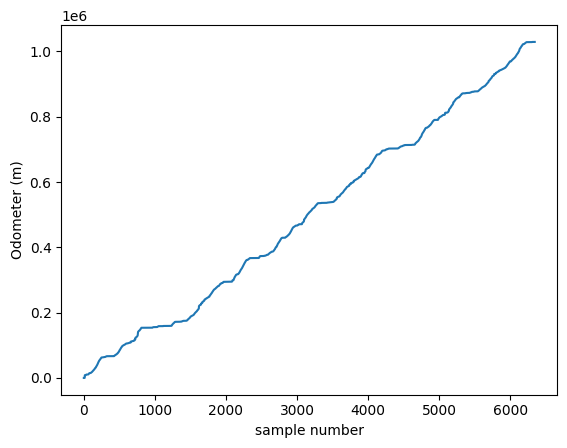

In [9]:
odometer=pd.DataFrame()
odometer_data=[]
x_axis=[]
date=[]
status=[]
#torch_codes_0204.info()

for i in range(0,df.shape[0]):
    #if int(df.iloc[i,3]>80000000):
    status.append(df.iloc[i,12])
    odometer_data.append(int(df.iloc[i,3]))
    date.append(df.iloc[i,4])
    x_axis.append(i)

#print(max(odometer_data),min(odometer_data))
odometer['sample_number']=x_axis
odometer['odometer']=odometer_data
odometer['date']=date
odometer['status']=status

plt.ylabel("Odometer (m)")
plt.xlabel('sample number')
#plt.xticks(range(0,5572,100),rotation=90)
plt.plot(x_axis,odometer_data)

odometer.to_csv(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\data\zonar\odometer.csv')

The lower peak was caused by MinsDiff=504.
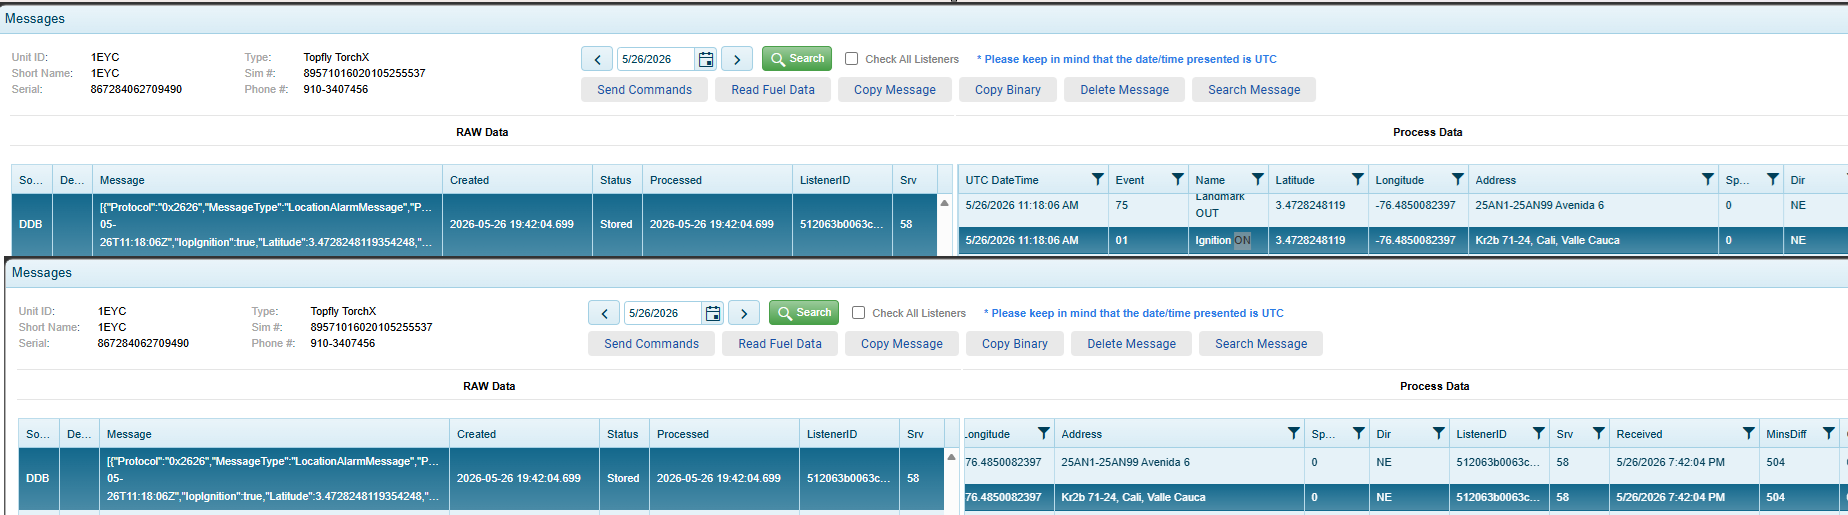

Speed

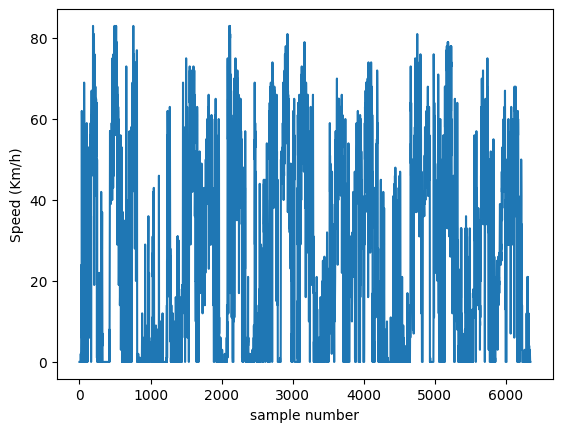

In [10]:
speed=pd.DataFrame()
speed_data=[]
x_axis=[]
date=[]
status=[]
#torch_codes_0204.info()

for i in range(0,df.shape[0]):                        
        status.append(df.iloc[i,12])
        speed_data.append(int(df.iloc[i,6]))
        date.append(df.iloc[i,4])
        x_axis.append(i)            

#print(max(speed_data),min(speed_data))
speed['sample_number']=x_axis
speed['speed']=speed_data
speed['status']=status

plt.ylabel("Speed (Km/h)")
plt.xlabel('sample number')
plt.plot(x_axis,speed_data)

speed.to_csv(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\data\zonar\speed.csv')

RPM

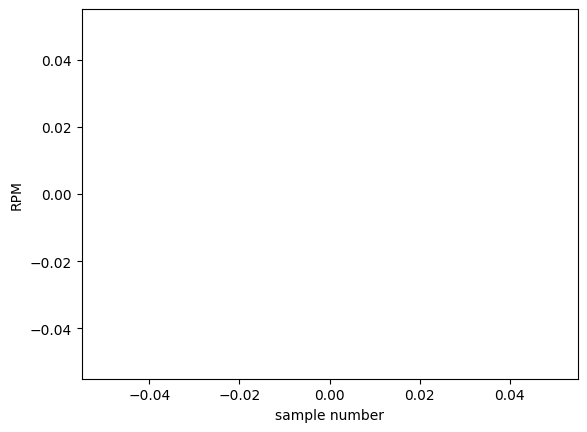

In [11]:
rpm=pd.DataFrame()
rpm_data=[]
x_axis=[]
date=[]
status=[]
#torch_codes_0204.info()

for i in range(0,df.shape[0]):
        if df.iloc[i,8]<65535:
                status.append(df.iloc[i,12])
                rpm_data.append(int(df.iloc[i,8]))
                date.append(df.iloc[i,4])
                x_axis.append(i)            

#print(max(rpm_data),min(rpm_data))
rpm['sample_number']=x_axis
rpm['rpm']=rpm_data
rpm['status']=status

plt.ylabel("RPM")
plt.xlabel('sample number')
plt.plot(x_axis,rpm_data)
#rpm.to_csv(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\data\zonar\rpm.csv')

Fuel

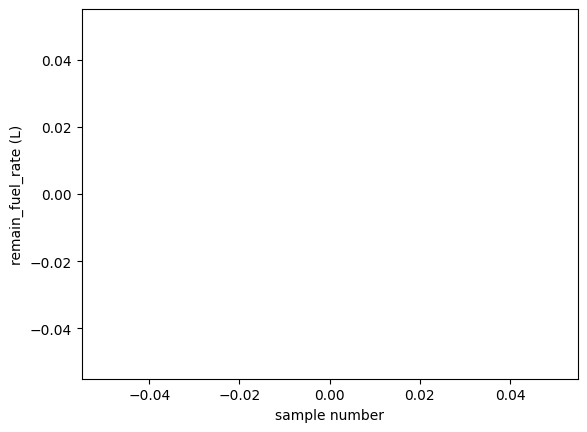

In [12]:
rfl=pd.DataFrame()
fuel_data=[]
x_axis=[]
date=[]
status=[]
status_aux=[]
#torch_codes_0204.info()

for i in range(0,df.shape[0]):
    if df.iloc[i,9]!='FF':               
        aux_data=df.iloc[i,12]
        if (len(aux_data)<170):
            status.append(df.iloc[i,12])
            x_axis.append(i) 
            fuel_data.append((int(df.iloc[i,9],16) & 127))
            date.append(df.iloc[i,4])

plt.plot(x_axis,fuel_data)
plt.ylabel("remain_fuel_rate (L)")
plt.xlabel('sample number')

rfl['fuel_data']=fuel_data
rfl['date']=date
rfl['raw_data']=status
#rfl.to_csv(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\data\zonar\rfl.csv',sep=',')

Fuel smoothing

Charth with averaging_sample number= 45


Text(0.5, 0, 'sample number')

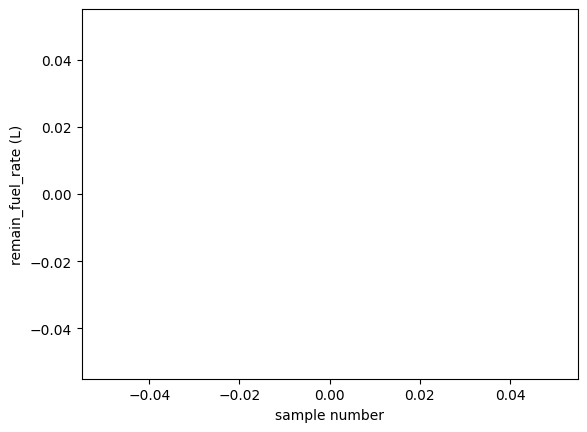

In [13]:
rfl=pd.DataFrame()
fuel_data=[]
x_axis=[]
x_axis_5=[]
date=[]
status=[]
status_aux=[]
aux_5=0
cont_5=0
avg_5=[]
i_5=0
averaging_sample=int(input("Typr the averaging sample number: "))

for i in range(0,df.shape[0]):
    if df.iloc[i,9]!='FF':               
        aux_data=df.iloc[i,12]
        if (len(aux_data)<170):
            status.append(df.iloc[i,12])
            x_axis.append(i) 
            fuel_data.append((int(df.iloc[i,9],16) & 127))
            date.append(df.iloc[i,4])
            aux_5=aux_5+(int(df.iloc[i,9],16) & 127)
            cont_5=cont_5+1
            if cont_5>averaging_sample:                   #Test
                i_5=i_5+1                
                cont_5=0
                avg_5.append(aux_5/5)
                aux_5=0
                x_axis_5.append(i_5)

print("Charth with averaging_sample number=",averaging_sample)

plt.plot(x_axis_5,avg_5)
plt.ylabel("remain_fuel_rate (L)")
plt.xlabel('sample number')

#rfl['fuel_data']=fuel_data
#rfl['date']=date
#rfl['raw_data']=status
#rfl.to_csv(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\data\zonar\rfl.csv',sep=',')

In [14]:
df.info()

<class 'pandas.DataFrame'>
Index: 6344 entries, 8382 to 1
Data columns (total 14 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   i_on         6344 non-null   int64  
 1   i_off        6344 non-null   int64  
 2   io           6344 non-null   str    
 3   odometer     6344 non-null   int64  
 4   date         6344 non-null   str    
 5   ext_ps       6344 non-null   float64
 6   speed        6344 non-null   int64  
 7   acc_fuel_c   6344 non-null   float64
 8   rpm          6344 non-null   int64  
 9   remain_fuel  6344 non-null   str    
 10  gnss         6344 non-null   int64  
 11  cool_temp    6344 non-null   int64  
 12  Status       6344 non-null   str    
 13  engine_load  6344 non-null   int64  
dtypes: float64(2), int64(8), str(4)
memory usage: 743.4 KB


Cooling fluid Temperature 

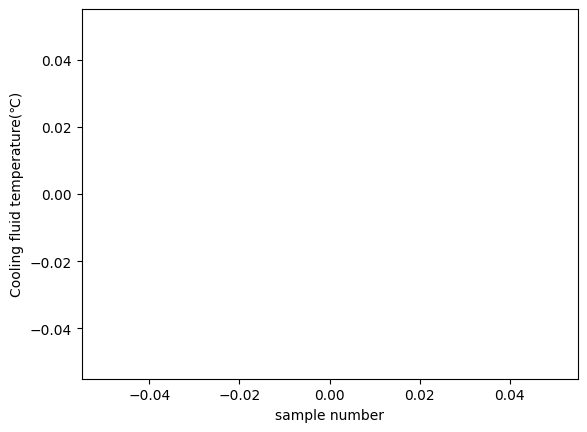

In [15]:
temp=pd.DataFrame()
temp_data=[]
x_axis=[]
date=[]
status=[]
#torch_codes_0204.info()

for i in range(0,df.shape[0]):
    if df.iloc[i,11]!=255:               
        aux_data=df.iloc[i,11]
        status.append(df.iloc[i,12])
        temp_data.append(df.iloc[i,11]-40)
        x_axis.append(i)         
        date.append(df.iloc[i,4])

#print(max(temp_data),min(temp_data))
temp['sample_number']=x_axis
temp['date']=date
temp['temp']=temp_data
temp['status']=status

plt.ylabel("Cooling fluid temperature(℃)")
plt.xlabel('sample number')
plt.plot(x_axis,temp_data)

#temp.to_csv(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\data\zonar\temp.csv')

Engine load

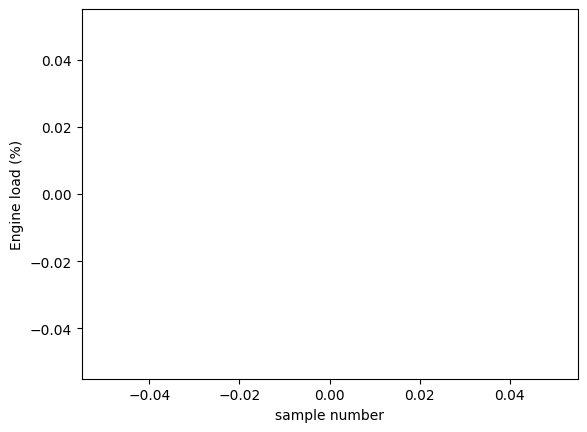

In [16]:
engine_load=pd.DataFrame()
engine_data=[]
x_axis=[]
date=[]
status=[]
#torch_codes_0204.info()

for i in range(0,df.shape[0]):
    if df.iloc[i,13]!=255:               
        aux_data=df.iloc[i,13]
        status.append(df.iloc[i,12])
        engine_data.append(df.iloc[i,13]-40)
        x_axis.append(i)         
        date.append(df.iloc[i,4])

#print(max(temp_data),min(temp_data))
engine_load['sample_number']=x_axis
engine_load['date']=date
engine_load['engine load %']=engine_data
engine_load['status']=status

plt.ylabel("Engine load (%)")
plt.xlabel('sample number')
plt.plot(x_axis,engine_data)

#temp.to_csv(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\data\zonar\engine.csv')


In [17]:
hl=pd.read_excel(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\data\zonar\historicallocations.xlsx')
hl.info()

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\Jose.Hurtado\\Documents\\Zonar_projects\\data\\zonar\\historicallocations.xlsx'

In [ ]:
hl['Eventos'].value_counts()

Eventos
Conduciendo             1051
Estacionado             1019
Inmóvil - Detenido       632
Saliendo de Landmark      63
Entrando a Landmark       62
Ignición Encendida        32
Ignición Apagada          31
Name: count, dtype: int64

Activities report

In [ ]:
ars=pd.read_csv(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\data\zonar\Activity Report_v3.csv',sep=',')
ars['MilesDriven_in_Miles']=0.0
cad_str_to_float=[]
ars.info()

<class 'pandas.DataFrame'>
RangeIndex: 394 entries, 0 to 393
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   GroupName             0 non-null      float64
 1   UnitName              394 non-null    str    
 2   StartTime             394 non-null    str    
 3   MovingTimeSecs        394 non-null    str    
 4   MilesDriven           388 non-null    str    
 5   MaxSpeed              394 non-null    int64  
 6   StopTime              394 non-null    str    
 7   textbox43             394 non-null    str    
 8   StopLengthSecs        394 non-null    str    
 9   ContactName           394 non-null    str    
 10  textbox45             394 non-null    str    
 11  textbox54             394 non-null    int64  
 12  textbox28             394 non-null    str    
 13  textbox29             394 non-null    str    
 14  textbox30             394 non-null    int64  
 15  textbox32             394 non-null

MilesDriven

In [ ]:
for i in range(0,ars.shape[0]):
    try:
        ars.iloc[i,4].replace(',','.')
    except:
        print("Data error on: ",ars.iloc[i,2])

Data error on:  29/05/2026 6:46 p.m.
Data error on:  29/05/2026 8:59 p.m.
Data error on:  30/05/2026 8:57 a.m.
Data error on:  30/05/2026 10:05 a.m.
Data error on:  30/05/2026 1:12 p.m.
Data error on:  31/05/2026 6:55 a.m.


In [ ]:
odometer.info()

<class 'pandas.DataFrame'>
RangeIndex: 19302 entries, 0 to 19301
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   sample_number  19302 non-null  int64
 1   odometer       19302 non-null  int64
 2   date           19302 non-null  str  
 3   status         19302 non-null  str  
dtypes: int64(2), str(2)
memory usage: 603.3 KB


In [ ]:
odometer_distance=odometer
odometer_cad=[]

for i in range(0,odometer.shape[0]):
    odometer_cad.append(str(odometer.iloc[i,2]))

odometer_distance['date str']=odometer_cad
odometer_distance.info()

value=input('Type the date to look for: ')
date_distance_error=odometer_distance[odometer_distance['date str'].str.contains(value)]
print(date_distance_error)

date_distance_error.to_csv(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\data\zonar\date_distance_error.csv')

<class 'pandas.DataFrame'>
RangeIndex: 19302 entries, 0 to 19301
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   sample_number  19302 non-null  int64
 1   odometer       19302 non-null  int64
 2   date           19302 non-null  str  
 3   status         19302 non-null  str  
 4   date str       19302 non-null  str  
dtypes: int64(2), str(3)
memory usage: 754.1 KB
       sample_number  odometer          date  \
876              876  86448842  260526202632   
2897            2897  86539205  260529122026   
5073            5073  86652541  260531202621   
7252            7252  86765322  260604012026   
8668            8668  86822043  260606012026   
9012            9012  86827239  260606202623   
10167          10167  86864000  260608202612   
10168          10168  86864000  260608202637   
11073          11073  86905500  260609202608   
13405          13405  87008888  260612192026   
14910          14910  87039124  2

StopLength

In [ ]:
stop_negative=ars[ars['StopLengthSecs'].str.contains('-')]
stop_negative.info()

<class 'pandas.DataFrame'>
RangeIndex: 0 entries
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   GroupName             0 non-null      float64
 1   UnitName              0 non-null      str    
 2   StartTime             0 non-null      str    
 3   MovingTimeSecs        0 non-null      str    
 4   MilesDriven           0 non-null      str    
 5   MaxSpeed              0 non-null      int64  
 6   StopTime              0 non-null      str    
 7   textbox43             0 non-null      str    
 8   StopLengthSecs        0 non-null      str    
 9   ContactName           0 non-null      str    
 10  textbox45             0 non-null      str    
 11  textbox54             0 non-null      int64  
 12  textbox28             0 non-null      str    
 13  textbox29             0 non-null      str    
 14  textbox30             0 non-null      int64  
 15  textbox32             0 non-null      str    


MaxSpeed

In [ ]:
for i in range(0,ars.shape[0]):
    if ars.iloc[i,5]<0:
        print(ars.iloc[i])